# Refugee Data: Exploratory Data Analysis (2008–2016)

This notebook explores UNHCR refugee population data, checks missing values, and compares the main host and origin countries.

In [23]:
import os
import pandas as pd

# Load cleaned UNHCR data
df = pd.read_csv(os.path.join("data", "unhcr_clean.csv"))

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (49798, 7)

Column names:
['year', 'host_country', 'origin_country', 'population_type', 'refugee_count', 'host_iso3', 'origin_iso3']

First 5 rows:


,year,host_country,origin_country,population_type,refugee_count,host_iso3,origin_iso3
0,2008,Australia,Afghanistan,Refugees (incl. refugee-like situations),4933.0,AUS,AFG
1,2008,Austria,Afghanistan,Refugees (incl. refugee-like situations),5387.0,AUT,AFG
2,2008,Azerbaijan,Afghanistan,Refugees (incl. refugee-like situations),125.0,AZE,AFG
3,2008,Belarus,Afghanistan,Refugees (incl. refugee-like situations),436.0,BLR,AFG
4,2008,Belgium,Afghanistan,Refugees (incl. refugee-like situations),196.0,BEL,AFG



Missing values:
year                  0
host_country          0
origin_country        0
population_type       0
refugee_count      2054
host_iso3           168
origin_iso3        2409
dtype: int64


In [24]:
# Check available years
print("Years:")
print(sorted(df["year"].unique()))

# Check population categories
print("\nPopulation types:")
print(df["population_type"].value_counts(dropna=False))

# Check duplicate records
duplicates = df.duplicated(
    subset=["year", "host_country", "origin_country"]
).sum()

print("\nDuplicate host-origin-year rows:", duplicates)

# Check missing refugee counts by year
print("\nMissing refugee counts by year:")
print(
    df.groupby("year")["refugee_count"]
      .apply(lambda x: x.isna().sum())
)

# Check missing country codes
print("\nHost countries with missing ISO3:")
print(
    df.loc[df["host_iso3"].isna(), "host_country"]
      .value_counts()
      .head(15)
)

print("\nOrigin countries with missing ISO3:")
print(
    df.loc[df["origin_iso3"].isna(), "origin_country"]
      .value_counts()
      .head(15)
)

Years:
[np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016)]

Population types:
population_type
Refugees (incl. refugee-like situations)    49798
Name: count, dtype: int64

Duplicate host-origin-year rows: 0

Missing refugee counts by year:
year
2008       0
2009       0
2010       0
2011       0
2012       0
2013       0
2014       0
2015       0
2016    2054
Name: refugee_count, dtype: int64

Host countries with missing ISO3:
host_country
Serbia and Kosovo (S/RES/1244 (1999))    166
Anguilla                                   2
Name: count, dtype: int64

Origin countries with missing ISO3:
origin_country
Palestinian                              703
Stateless                                505
Serbia and Kosovo (S/RES/1244 (1999))    447
Various/Unknown                          381
Lao People's Dem. Rep.                   132
Western Sahara                           127
Tibetan                   

In [25]:
# Inspect missing refugee counts in 2016
df_2016 = df[df["year"] == 2016].copy()

print("Total rows in 2016:", len(df_2016))
print("Missing counts:", df_2016["refugee_count"].isna().sum())

print("\nSample rows with missing counts:")
display(
    df_2016[df_2016["refugee_count"].isna()].head(15)
)

print("\nTop host countries with missing counts:")
print(
    df_2016.loc[
        df_2016["refugee_count"].isna(), "host_country"
    ].value_counts().head(15)
)

print("\nTop origin countries with missing counts:")
print(
    df_2016.loc[
        df_2016["refugee_count"].isna(), "origin_country"
    ].value_counts().head(15)
)

print("\nMissing percentage in 2016:")
print(
    round(df_2016["refugee_count"].isna().mean() * 100, 2),
    "%"
)

Total rows in 2016: 6822
Missing counts: 2054

Sample rows with missing counts:


,year,host_country,origin_country,population_type,refugee_count,host_iso3,origin_iso3
42977,2016,Algeria,Afghanistan,Refugees (incl. refugee-like situations),NaN,DZA,AFG
42990,2016,Cayman Islands,Afghanistan,Refugees (incl. refugee-like situations),NaN,CYM,AFG
42991,2016,Chad,Afghanistan,Refugees (incl. refugee-like situations),NaN,TCD,AFG
42993,2016,China,Afghanistan,Refugees (incl. refugee-like situations),NaN,CHN,AFG
42994,2016,"China, Hong Kong SAR",Afghanistan,Refugees (incl. refugee-like situations),NaN,HKG,AFG
42996,2016,Costa Rica,Afghanistan,Refugees (incl. refugee-like situations),NaN,CRI,AFG
43002,2016,Dominican Rep.,Afghanistan,Refugees (incl. refugee-like situations),NaN,DOM,AFG
43005,2016,Ethiopia,Afghanistan,Refugees (incl. refugee-like situations),NaN,ETH,AFG
43009,2016,Georgia,Afghanistan,Refugees (incl. refugee-like situations),NaN,GEO,AFG
43031,2016,Madagascar,Afghanistan,Refugees (incl. refugee-like situations),NaN,MDG,AFG



Top host countries with missing counts:
host_country
South Africa      42
United Kingdom    42
Finland           39
Argentina         39
Australia         38
Switzerland       37
Peru              35
Ireland           33
Germany           33
Austria           33
New Zealand       32
Denmark           31
Norway            31
Sweden            31
Portugal          31
Name: count, dtype: int64

Top origin countries with missing counts:
origin_country
Ethiopia         32
Congo            30
Côte d'Ivoire    30
Cameroon         28
Algeria          28
Liberia          28
Nigeria          28
Pakistan         27
Sudan            27
Sierra Leone     27
Burundi          26
Egypt            26
Chad             25
Somalia          24
Uganda           24
Name: count, dtype: int64

Missing percentage in 2016:
30.11 %


In [26]:
# Check 2016 missing values by host country
host_missing = (
    df[df["year"] == 2016]
    .groupby("host_country")
    .agg(
        total_rows=("refugee_count", "size"),
        missing_rows=("refugee_count", lambda x: x.isna().sum())
    )
)

host_missing["missing_pct"] = (
    host_missing["missing_rows"] /
    host_missing["total_rows"] * 100
)

# Show countries with the highest reported refugee totals
top_hosts = (
    df.groupby("host_country")["refugee_count"]
    .sum(min_count=1)
    .nlargest(10)
    .index
)

display(host_missing.reindex(top_hosts))

,total_rows,missing_rows,missing_pct
host_country,,,
Pakistan,24,7,29.166667
Iran (Islamic Rep. of),6,0,0.000000
Turkey,81,18,22.222222
Jordan,48,12,25.000000
Syrian Arab Rep.,47,6,12.765957
Lebanon,62,10,16.129032
Germany,167,33,19.760479
Kenya,38,10,26.315789
Ethiopia,27,7,25.925926


In [27]:
# Check 2016 missing values by origin country
origin_missing = (
    df[df["year"] == 2016]
    .groupby("origin_country")
    .agg(
        total_rows=("refugee_count", "size"),
        missing_rows=("refugee_count", lambda x: x.isna().sum())
    )
)

origin_missing["missing_pct"] = (
    origin_missing["missing_rows"] /
    origin_missing["total_rows"] * 100
)

# Show origins with the highest reported refugee totals
top_origins = (
    df.groupby("origin_country")["refugee_count"]
    .sum(min_count=1)
    .nlargest(10)
    .index
)

display(origin_missing.reindex(top_origins))

,total_rows,missing_rows,missing_pct
origin_country,,,
Afghanistan,104,18,17.307692
Syrian Arab Rep.,131,20,15.267176
Iraq,112,15,13.392857
Somalia,119,24,20.168067
Sudan,112,27,24.107143
Dem. Rep. of the Congo,107,19,17.757009
Myanmar,51,11,21.568627
Colombia,47,9,19.148936
South Sudan,55,22,40.000000


In [28]:
# Calculate annual refugee totals
host_year = (
    df.groupby(["host_country", "year"])["refugee_count"]
    .sum(min_count=1)
    .reset_index(name="refugee_total")
)

origin_year = (
    df.groupby(["origin_country", "year"])["refugee_count"]
    .sum(min_count=1)
    .reset_index(name="refugee_total")
)

# Rank countries by average annual refugee population
host_ranking = (
    host_year.groupby("host_country")
    .agg(
        average_refugees=("refugee_total", "mean"),
        years_available=("refugee_total", "count")
    )
    .sort_values("average_refugees", ascending=False)
)

origin_ranking = (
    origin_year.groupby("origin_country")
    .agg(
        average_refugees=("refugee_total", "mean"),
        years_available=("refugee_total", "count")
    )
    .sort_values("average_refugees", ascending=False)
)

print("TOP 10 HOST COUNTRIES")
display(host_ranking.head(10))

print("\nTOP 10 ORIGIN COUNTRIES")
display(origin_ranking.head(10))

TOP 10 HOST COUNTRIES


,average_refugees,years_available
host_country,,
Pakistan,1.644352e+06,9
Iran (Islamic Rep. of),9.641029e+05,9
Turkey,8.801173e+05,9
Jordan,5.334613e+05,9
Syrian Arab Rep.,5.263254e+05,9
Lebanon,4.829132e+05,9
Germany,4.802541e+05,9
Kenya,4.783486e+05,9
Ethiopia,4.051292e+05,9



TOP 10 ORIGIN COUNTRIES


,average_refugees,years_available
origin_country,,
Afghanistan,2.705115e+06,9
Syrian Arab Rep.,1.950437e+06,9
Iraq,9.887040e+05,9
Somalia,9.541136e+05,9
Sudan,5.373636e+05,9
South Sudan,5.055127e+05,6
Dem. Rep. of the Congo,4.885078e+05,9
Myanmar,4.152701e+05,9
Colombia,3.730134e+05,9


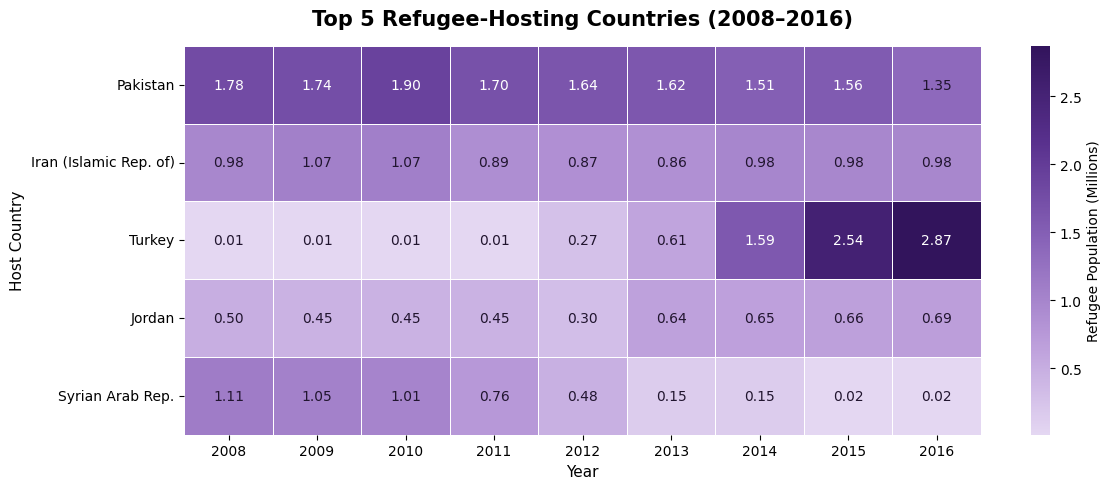

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

# Create a darker purple palette
purple_cmap = LinearSegmentedColormap.from_list(
    "custom_purples",
    ["#E4D7F2", "#B99AD9", "#8863B8", "#59318E", "#32145C"]
)

# Select top 5 host countries
top5_hosts = host_ranking.head(5).index.tolist()

# Prepare heatmap data
heatmap_data = (
    host_year[host_year["host_country"].isin(top5_hosts)]
    .pivot(index="host_country", columns="year", values="refugee_total")
    .reindex(top5_hosts)
    / 1_000_000
)

# Create heatmap
fig, ax = plt.subplots(figsize=(12, 5))

heatmap = sns.heatmap(
    heatmap_data,
    cmap=purple_cmap,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Refugee Population (Millions)"},
    ax=ax
)

# Adjust annotation colors for readability
norm = heatmap.collections[0].norm

for text in heatmap.texts:
    x, y = text.get_position()
    col = int(x - 0.5)
    row = int(y - 0.5)

    value = heatmap_data.iloc[row, col]
    rgba = purple_cmap(norm(value))

    luminance = (
        0.2126 * rgba[0]
        + 0.7152 * rgba[1]
        + 0.0722 * rgba[2]
    )

    text.set_color("white" if luminance < 0.45 else "#21152F")
    text.set_fontsize(10)

# Add titles and labels
ax.set_title(
    "Top 5 Refugee-Hosting Countries (2008–2016)",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("Host Country", fontsize=11)

ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

# Save figure
plt.tight_layout()
plt.savefig(
    "figure1_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Figure 1 – Heatmap

This heatmap shows the refugee populations of the top 5 host countries from 2008 to 2016. The colors represent the number of refugees in each country for each year. Darker purple indicates a higher refugee population.

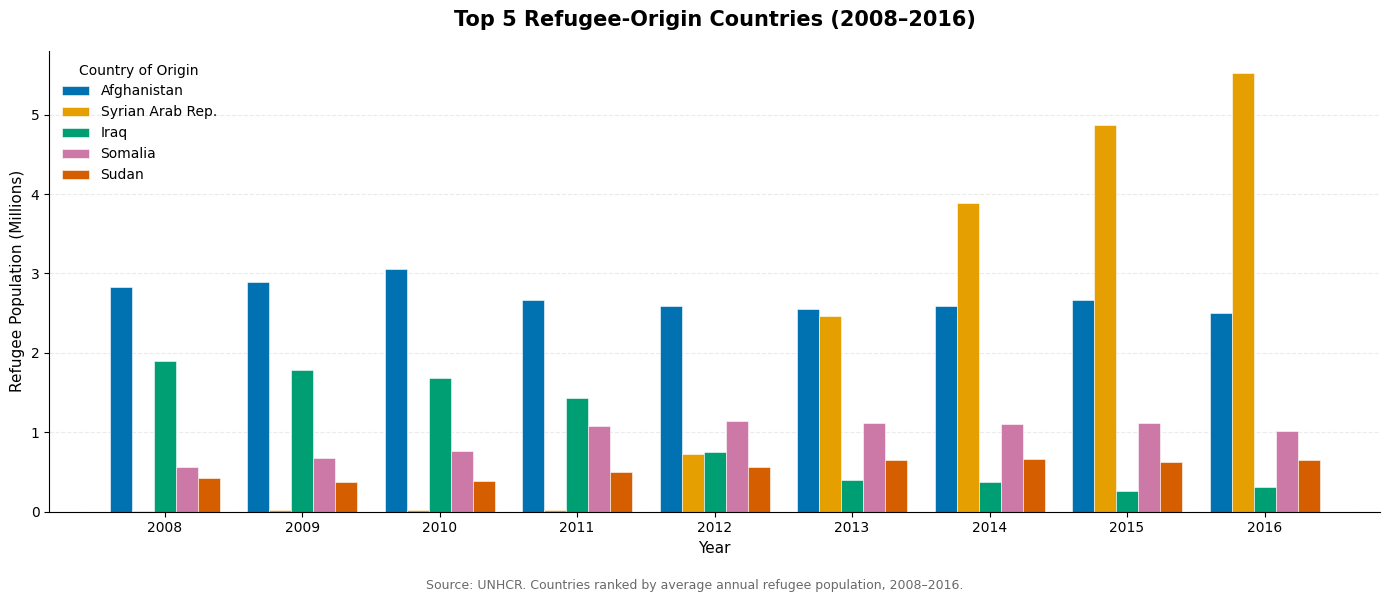

In [30]:
import matplotlib.pyplot as plt
import numpy as np

# Select top 5 origin countries
top5_origins = origin_ranking.head(5).index.tolist()

# Prepare annual refugee totals
bar_data = (
    origin_year[origin_year["origin_country"].isin(top5_origins)]
    .pivot(index="year", columns="origin_country", values="refugee_total")
    .reindex(index=range(2008, 2017), columns=top5_origins)
    / 1_000_000
)

# Colorblind-friendly palette
colors = [
    "#0072B2",  # Blue
    "#E69F00",  # Orange
    "#009E73",  # Bluish green
    "#CC79A7",  # Reddish purple
    "#D55E00"   # Vermillion
]

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(14, 6))

years = bar_data.index.to_numpy()
x = np.arange(len(years))
bar_width = 0.16

for i, country in enumerate(top5_origins):
    positions = x + (i - 2) * bar_width

    ax.bar(
        positions,
        bar_data[country],
        width=bar_width,
        label=country,
        color=colors[i],
        edgecolor="white",
        linewidth=0.4
    )

# Add titles and labels
ax.set_title(
    "Top 5 Refugee-Origin Countries (2008–2016)",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("Refugee Population (Millions)", fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(years)

ax.legend(
    title="Country of Origin",
    loc="upper left",
    frameon=False
)

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Add source note
fig.text(
    0.5, 0.01,
    "Source: UNHCR. Countries ranked by average annual refugee population, 2008–2016.",
    ha="center",
    fontsize=9,
    color="dimgray"
)

# Save figure
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(
    "figure2_bar_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Figure 2 – Grouped Bar Chart

This grouped bar chart shows the refugee populations from the top 5 countries of origin between 2008 and 2016. Each color represents a different country, allowing us to compare refugee numbers across countries and years.